# Notebook 03 — Limpieza de Datos Industriales (Sin Data Leakage)

## Sensores Virtuales y Analizadores en Línea

Regla crítica en series temporales de planta: **nunca calcular cuantiles de recorte ni medianas de imputación usando datos del futuro**.
En este notebook aplicamos en orden estricto:
1. Eliminación de duplicados SCADA (`drop_duplicates`).
2. Depuración física de errores de laboratorio imposibles (`flash_point_lab_C <= 0` o `>= 100`), **preservando** excursiones operativas reales fuera de especificación (`< 38 °C` y `> 60 °C`).
3. Ajuste de límites `P1–P99` y medianas **exclusivamente sobre la ventana de entrenamiento (primeros 65%)** antes de transformar validación y prueba.
4. Conservación íntegra de nulos del objetivo para no fabricar etiquetas sintéticas al evaluar.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8-whitegrid")
COLORS = ["#007297", "#8EC14B", "#E8820C", "#C0392B", "#0D202B"]
WORK_DIR = "/content" if os.path.isdir("/content") else "."

DATA_URL = "https://d29ikw7e1z6k4e.cloudfront.net/curso_sensor/curso_sensor_raw_data.csv"
df_raw = pd.read_csv(DATA_URL)
print(f"Dataset original: {df_raw.shape[0]} filas x {df_raw.shape[1]} columnas")
print(f"Duplicados SCADA detectados: {df_raw.duplicated().sum()}")
print(f"Valores faltantes totales  : {df_raw.isna().sum().sum()}")

Dataset original: 1098 filas x 17 columnas
Duplicados SCADA detectados: 3
Valores faltantes totales  : 199


In [2]:
# Paso 1: Eliminar retransmisiones duplicadas manteniendo el orden cronológico
df = df_raw.drop_duplicates().reset_index(drop=True)
print(f"Filas únicas tras deduplicación: {len(df)} (eliminados {len(df_raw) - len(df)} duplicados)")

Filas únicas tras deduplicación: 1095 (eliminados 3 duplicados)


### Paso 2: Validación Física del Objetivo (`flash_point_lab_C`)
Un *flash point* de `-4.5 °C` o `148.0 °C` es físicamente incompatible con keroseno de destilación atmosférica (error de transcripción). Los convertimos en `NaN`, mientras conservamos lecturas reales fuera de especificación como `35 °C` o `64 °C`.

In [3]:
invalid_fp_mask = (df["flash_point_lab_C"] <= 0) | (df["flash_point_lab_C"] >= 100)
print(f"Errores físicos de laboratorio detectados: {invalid_fp_mask.sum()}")
print(df.loc[invalid_fp_mask, ["date", "flash_point_lab_C"]])

df.loc[invalid_fp_mask, "flash_point_lab_C"] = np.nan

Errores físicos de laboratorio detectados: 2
                    date  flash_point_lab_C
185  2025-03-03 16:00:00               -4.5
532  2025-06-27 08:00:00              148.0


In [4]:
# Paso 3: Definir frontera cronológica ANTES de ajustar estadística alguna (cero leakage)
n_total = len(df)
n_train = int(n_total * 0.65)   # Primeros 65% turnos -> Entrenamiento
n_val   = int(n_total * 0.80)   # Siguientes 15% turnos -> Validación; últimos 20% -> Prueba

df["split"] = np.where(df.index < n_train, "train", np.where(df.index < n_val, "val", "test"))
print(f"Frontera cronológica: Train=0..{n_train-1} ({n_train} turnos), Val={n_train}..{n_val-1} ({n_val-n_train} turnos), Test={n_val}..{n_total-1} ({n_total-n_val} turnos)")

Frontera cronológica: Train=0..710 (711 turnos), Val=711..875 (165 turnos), Test=876..1094 (219 turnos)


In [5]:
# Paso 4: Auditoría IQR x2.5 y recorte P1-P99 ajustados SOLO sobre Train
proc_cols = [c for c in df.select_dtypes(include=[np.number]).columns if c != "flash_point_lab_C"]
df_clean = df.copy()

print(f"{'Variable':<28} {'Outliers IQR(2.5)':<18} {'P01 (Train)':<13} {'P99 (Train)':<13} {'Recortados'}")
print("-" * 82)
for col in proc_cols:
    s_tr = df_clean.loc[:n_train-1, col].dropna()
    q1, q3 = s_tr.quantile(0.25), s_tr.quantile(0.75)
    iqr = q3 - q1
    n_iqr = int(((df_clean[col] < q1 - 2.5 * iqr) | (df_clean[col] > q3 + 2.5 * iqr)).sum())
    p01, p99 = float(s_tr.quantile(0.01)), float(s_tr.quantile(0.99))
    n_clip = int(((df_clean[col] < p01) | (df_clean[col] > p99)).sum())
    df_clean[col] = df_clean[col].clip(lower=p01, upper=p99)
    print(f"{col:<28} {n_iqr:<18} {p01:<13.2f} {p99:<13.2f} {n_clip}")

Variable                     Outliers IQR(2.5)  P01 (Train)   P99 (Train)   Recortados
----------------------------------------------------------------------------------
feed_flow_rate_m3h           1                  908.62        997.21        20
feed_temperature_C           1                  360.90        370.20        38
column_top_temp_C            0                  107.30        112.70        14
column_top_pressure_kPag     1                  106.15        114.13        19
column_delta_p_kPa           1                  18.20         22.10         25
tray_15_temp_C               1                  193.20        208.43        30
kerosene_draw_temp_C         4                  173.11        186.40        56
column_bottom_temp_C         0                  350.32        365.00        27
reflux_flow_m3h              1                  274.60        326.20        16
reflux_ratio                 0                  1.92          2.29          20
kerosene_product_flow_m3h    0          

In [6]:
# Paso 5: Imputación de sensores de proceso con mediana calculada SOLO en Train
train_medians = df_clean.loc[:n_train-1, proc_cols].median()
df_clean[proc_cols] = df_clean[proc_cols].fillna(train_medians)

print(f"Nulos restantes en variables de entrada: {df_clean[proc_cols].isna().sum().sum()}")
print(f"Turnos con laboratorio válido disponible : {df_clean['flash_point_lab_C'].notna().sum()} / {len(df_clean)}")
print("(Nota: NO imputamos ni interpolamos la variable objetivo en val/test para evaluar con datos reales de laboratorio)")

Nulos restantes en variables de entrada: 0
Turnos con laboratorio válido disponible : 1031 / 1095
(Nota: NO imputamos ni interpolamos la variable objetivo en val/test para evaluar con datos reales de laboratorio)


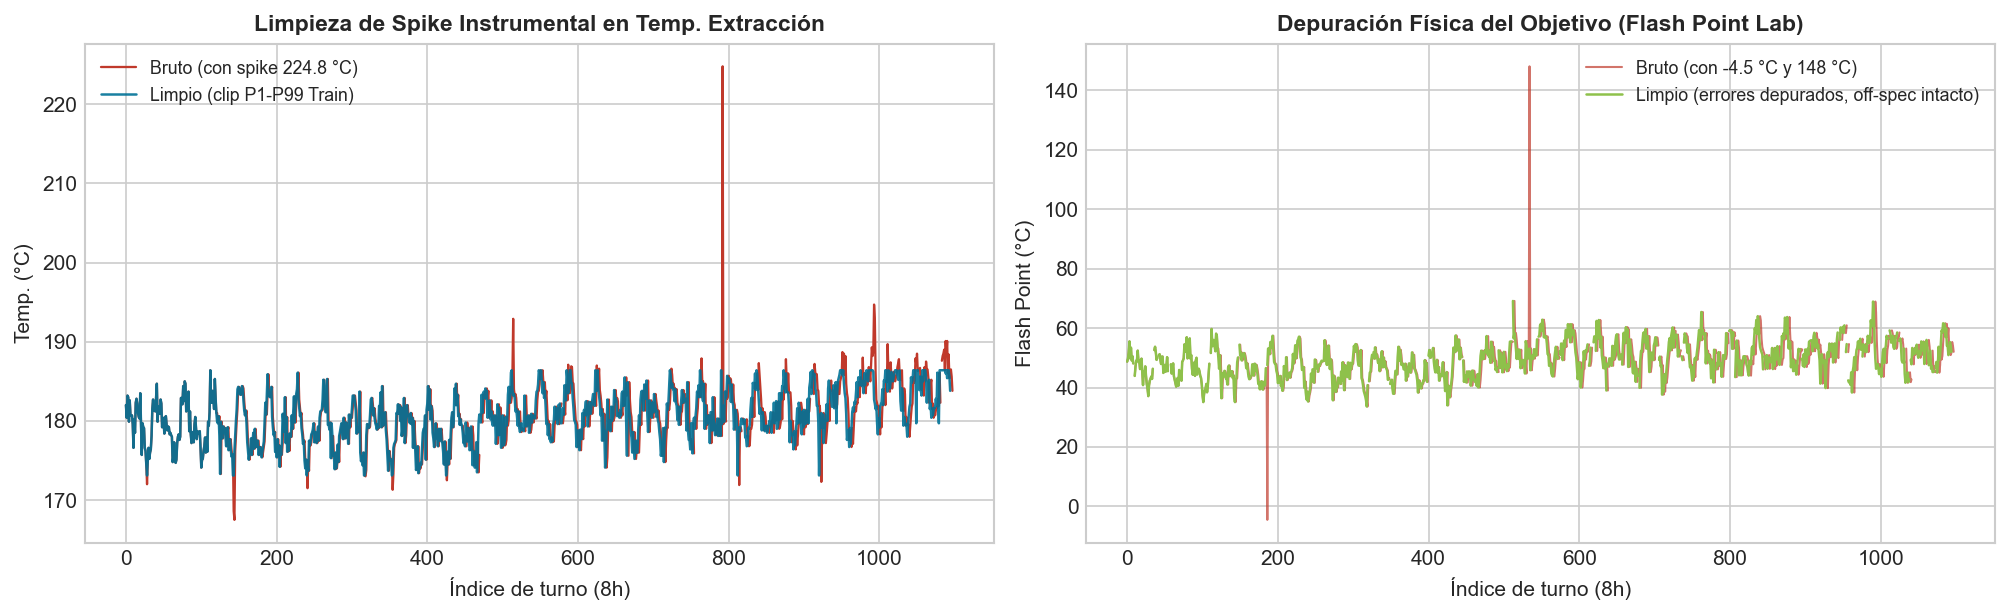

Dataset limpio guardado en: /Users/santiagozapata/pungo-academy/course-production/sensores-virtuales/notebooks/sensor_clean.csv


In [7]:
# Paso 6: Comparativa visual antes vs después y guardado
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.2), dpi=150)
axes[0].plot(df_raw["kerosene_draw_temp_C"], color=COLORS[3], linewidth=1.1, label="Bruto (con spike 224.8 °C)")
axes[0].plot(df_clean["kerosene_draw_temp_C"], color=COLORS[0], linewidth=1.2, alpha=0.9, label="Limpio (clip P1-P99 Train)")
axes[0].set_title("Limpieza de Spike Instrumental en Temp. Extracción", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Índice de turno (8h)")
axes[0].set_ylabel("Temp. (°C)")
axes[0].legend(fontsize=8.5)

axes[1].plot(df_raw["flash_point_lab_C"], color=COLORS[3], linewidth=1.0, alpha=0.7, label="Bruto (con -4.5 °C y 148 °C)")
axes[1].plot(df_clean["flash_point_lab_C"], color=COLORS[1], linewidth=1.2, label="Limpio (errores depurados, off-spec intacto)")
axes[1].set_title("Depuración Física del Objetivo (Flash Point Lab)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Índice de turno (8h)")
axes[1].set_ylabel("Flash Point (°C)")
axes[1].legend(fontsize=8.5)

plt.tight_layout()
plt.show()

out_clean = os.path.join(WORK_DIR, "sensor_clean.csv")
df_clean.to_csv(out_clean, index=False)
print(f"Dataset limpio guardado en: {os.path.abspath(out_clean)}")

### Checkpoint: Lo que debes ver

- **1,095 turnos únicos** preservando exactamente las tres particiones temporales (`train`, `val`, `test`)
- Spikes instrumentales (`224.8 °C`, `236.1 m³/h`, `327 kg/h`, etc.) recortados usando exclusivamente percentiles `P1–P99` del entrenamiento
- Archivo `sensor_clean.csv` guardado y listo para el Notebook 04